## 1. Imports and Configuration

In [1]:
%pip install pydicom monai

Note: you may need to restart the kernel to use updated packages.


In [2]:
# [IMPORTS]
import os
import numpy as np
import pandas as pd
import torch
import monai.transforms as mt
import pydicom
from pathlib import Path
import matplotlib.pyplot as plt
from scipy import stats

/opt/anaconda3/envs/ml_tutorial_env/lib/python3.13/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [3]:
# [CONFIG]
KL_DIVERGENCE = '../../data/baseline/kl_divergence_beta_5.00e-05.csv'
CHECKPOINT_PATH = '../../models/checkpoints/beta_5.00e-05_best.pth'
MASK_PATH = '../../data/masks/rmask_ICV.nii'
IMAGES_ROOT     = '../../data/raw/ppmi_images'  # parent folder of PD/Cont/SWEDD
OUTPUT_DIR      = '../../results/augmentation/'
FIGURES_DIR     = '../../results/figures/'
os.makedirs(OUTPUT_DIR,  exist_ok=True)
os.makedirs(FIGURES_DIR, exist_ok=True)

N_SUBJECTS   = 100
RANDOM_STATE = 42
DEVICE = 'cuda' if torch.cuda.is_available() else 'cpu'

print(f"Device: {DEVICE}")
print(f"Checkpoint: {CHECKPOINT_PATH}")
print(f"Images root: {IMAGES_ROOT}")

Device: cpu
Checkpoint: ../../models/checkpoints/beta_5.00e-05_best.pth
Images root: ../../data/raw/ppmi_images


## 2. Load Model

The β-VAE was trained by Professor Presotto and saved as beta_5.00e-05_best.pth. I copied selected_model.py from the training repository into our project to access the decoder and wrapper classes.

The encoder required a custom definition (CustomEncoder) because the checkpoint architecture differs slightly from the original BottleneckEncoder — specifically it has no channel reduction blocks. The encoder outputs a 512-dimensional vector which BottleneckAE splits into a 256-dimensional mean (mu) and log-variance. During inference only mu is used, giving a deterministic 256-dimensional latent representation per scan.

In [4]:
# Check the Checkpoint
import torch
checkpoint = torch.load(CHECKPOINT_PATH, map_location='cpu')
encoder_keys = [k for k in checkpoint.keys() if 'encoder' in k]
for k in encoder_keys:
    print(k, checkpoint[k].shape)

encoder.backbone.down1.0.block.conv.weight torch.Size([32, 1, 3, 3, 3])
encoder.backbone.down1.0.block.conv.bias torch.Size([32])
encoder.backbone.down1.0.block.bn.weight torch.Size([32])
encoder.backbone.down1.0.block.bn.bias torch.Size([32])
encoder.backbone.down1.0.block.bn.running_mean torch.Size([32])
encoder.backbone.down1.0.block.bn.running_var torch.Size([32])
encoder.backbone.down1.0.block.bn.num_batches_tracked torch.Size([])
encoder.backbone.down1.1.block.conv.weight torch.Size([32, 32, 3, 3, 3])
encoder.backbone.down1.1.block.conv.bias torch.Size([32])
encoder.backbone.down1.1.block.bn.weight torch.Size([32])
encoder.backbone.down1.1.block.bn.bias torch.Size([32])
encoder.backbone.down1.1.block.bn.running_mean torch.Size([32])
encoder.backbone.down1.1.block.bn.running_var torch.Size([32])
encoder.backbone.down1.1.block.bn.num_batches_tracked torch.Size([])
encoder.backbone.down2.0.block.conv.weight torch.Size([64, 32, 3, 3, 3])
encoder.backbone.down2.0.block.conv.bias torch

In [5]:
# Check the Encoder and Decoder
import sys
sys.path.append('../../models')
import inspect
from autoencoder.selected_model import BottleneckEncoder, ComplexBottleneckDeconvDecoder, BottleneckAE

# print(inspect.getsource(BottleneckEncoder))
print(inspect.getsource(BottleneckAE))

class BottleneckAE(nn.Module):
    def __init__(self, encoder, decoder):
        super().__init__()
        self.encoder = encoder
        self.decoder = decoder
    def forward(self, x):
        z = self.encoder(x)
        return self.decoder(z)



In [6]:
# Check the KL Divergence
import pandas as pd
df_kl = pd.read_csv(KL_DIVERGENCE)
print(f"Total dimensions: {len(df_kl)}")
print(df_kl.head())

Total dimensions: 256
  dimension   mean_kl
0  latent_0  0.013907
1  latent_1  0.004226
2  latent_2  0.122685
3  latent_3  0.096220
4  latent_4  0.013870


In [7]:
import torch.nn as nn

# [VAE-WRAPPER]
# ─────────────────────────────────────────────────────────────────
# BottleneckAE.forward passes the full encoder output directly to
# the decoder. Since our CustomEncoder returns (mu, log_var), we
# need a wrapper that:
# 1. Extracts only mu for the decoder (deterministic inference)
# 2. Exposes an encode() method that returns mu directly
# ─────────────────────────────────────────────────────────────────

class VAEWrapper(nn.Module):
    def __init__(self, model):
        super().__init__()
        self.model = model

    def encode(self, x):
        out = self.model.encoder(x)
        mu = out[0] if isinstance(out, (tuple, list)) else out
        return mu  # shape (1, 256)

    def decode(self, z):
        # conv_transpose3d needs (B, C, D, H, W) — reshape flat latent to (B, 256, 1, 1, 1)
        if z.dim() == 2:
            z = z.unsqueeze(-1).unsqueeze(-1).unsqueeze(-1)  # → (1, 256, 1, 1, 1)
        return self.model.decoder(z)

    def forward(self, x):
        mu = self.encode(x)
        recon = self.decode(mu)
        return recon, mu

In [8]:
import sys
sys.path.append('../../models')
import importlib
import autoencoder.custom_encoder
importlib.reload(autoencoder.custom_encoder)
from autoencoder.custom_encoder import CustomEncoder
from autoencoder.selected_model import (
    BottleneckAE, ComplexBottleneckDeconvDecoder
)


def load_model(checkpoint_path, device='cpu'):
    encoder = CustomEncoder(initial_filters=32, latent_dim=256)
    decoder = ComplexBottleneckDeconvDecoder(latent_dim=256, target_shape=(64, 128, 128))
    base    = BottleneckAE(encoder, decoder)
    ckpt    = torch.load(checkpoint_path, map_location=device)
    base.load_state_dict(ckpt)
    base.eval()
    wrapped = VAEWrapper(base)
    wrapped.eval()
    # quick smoke test — catches tuple-to-decoder bug immediately
    dummy = torch.zeros(1, 1, 64, 128, 128, device=device)
    with torch.no_grad():
        recon, mu = wrapped(dummy)
    assert isinstance(recon, torch.Tensor), "decoder returned non-Tensor"
    assert isinstance(mu,    torch.Tensor), "encoder returned non-Tensor mu"
    print(f"Smoke test passed  recon {tuple(recon.shape)}  mu {tuple(mu.shape)}")
    return wrapped

model = load_model(CHECKPOINT_PATH, DEVICE)
vae = VAEWrapper(model)
vae.eval()
print("VAEWrapper ready")
print(f"Encode output dim: 256")

Smoke test passed  recon (1, 1, 64, 128, 128)  mu (1, 256)
VAEWrapper ready
Encode output dim: 256


## 3. Load Images and Select 100 Subjects

In [9]:
# [LOAD-IMAGES]

IMAGE_ROOT = Path('../../data/raw/ppmi_images')
GROUPS = {
    'PD':    IMAGE_ROOT / 'PPMI_Images_PD',
    'HC':    IMAGE_ROOT / 'PPMI_Images_Cont',
    'SWEDD': IMAGE_ROOT / 'PPMI_Images_SWEDD'
}

def find_dcm_files(root_dir, label):
    """Recursively find all .dcm files and extract PATNO."""
    records = []
    for dcm_path in Path(root_dir).rglob('*.dcm'):
        parts = dcm_path.parts
        # PATNO is the first subfolder under the group root
        relative = dcm_path.relative_to(root_dir)
        patno = relative.parts[0]
        records.append({
            'PATNO':    patno,
            'label':    label,
            'dcm_path': str(dcm_path)
        })
    return records

print("Scanning image folders...")
records = []
for label, folder in GROUPS.items():
    found = find_dcm_files(folder, label)
    print(f"  {label}: {len(found)} scans found")

    records.extend(found)
print("Records", records)
df_images = pd.DataFrame(records)
df_images = df_images.drop_duplicates(subset=['PATNO'], keep='first')

print(f"\nTotal unique subjects: {len(df_images)}")
print(df_images['label'].value_counts().to_string())
print(f"\nSample paths:")
print(df_images['dcm_path'].head(3).to_string())

# Select 100 subjects — stratified by group
np.random.seed(RANDOM_STATE)
n_per_group = {'PD': 70, 'HC': 20, 'SWEDD': 10}
selected = []
for label, n in n_per_group.items():
    group = df_images[df_images['label'] == label]
    n = min(n, len(group))
    selected.append(group.sample(n, random_state=RANDOM_STATE))

df_selected = pd.concat(selected).reset_index(drop=True)
print(f"\nSelected {len(df_selected)} subjects:")
print(df_selected['label'].value_counts().to_string())

Scanning image folders...
  PD: 1222 scans found
  HC: 378 scans found
  SWEDD: 136 scans found
Records [{'PATNO': '172854', 'label': 'PD', 'dcm_path': '../../data/raw/ppmi_images/PPMI_Images_PD/172854/Reconstructed_DaTSCAN/2022-09-30_12_51_28.0/I1632125/PPMI_172854_NM_Reconstructed_DaTSCAN_Br_20221019121702557_1_S1167989_I1632125.dcm'}, {'PATNO': '174996', 'label': 'PD', 'dcm_path': '../../data/raw/ppmi_images/PPMI_Images_PD/174996/Reconstructed_DaTSCAN/2023-04-10_12_01_34.0/I1697979/PPMI_174996_NM_Reconstructed_DaTSCAN_Br_20230508142952090_1_S1220249_I1697979.dcm'}, {'PATNO': '142631', 'label': 'PD', 'dcm_path': '../../data/raw/ppmi_images/PPMI_Images_PD/142631/Reconstructed_DaTSCAN/2022-02-15_14_29_07.0/I1562666/PPMI_142631_NM_Reconstructed_DaTSCAN_Br_20220330192012701_1_S1118837_I1562666.dcm'}, {'PATNO': '137450', 'label': 'PD', 'dcm_path': '../../data/raw/ppmi_images/PPMI_Images_PD/137450/Reconstructed_DaTSCAN/2022-09-13_12_53_28.0/I1644916/PPMI_137450_NM_Reconstructed_DaTSCAN_Br_

## 4. Load DICOM

In [10]:
# [NORMALISATION]
import nibabel as nib

_mask_img = nib.load(MASK_PATH)
_mask = _mask_img.get_fdata().astype(bool)   # shape (91, 109, 91)

def normalize_volume(vol: np.ndarray) -> np.ndarray:
    """
    Replicates Prof. Presotto's training-time normalisation exactly:
      1. Shift minimum to zero
      2. Zero out outside-brain voxels using ICV mask
      3. Divide by mean of within-brain voxels
    vol must be shape (91, 109, 91) — i.e. before crop/pad.
    """
    vol = vol - vol.min()
    vol = vol * _mask
    vol = vol / np.mean(vol[_mask])
    return vol

In [11]:
# [LOAD-DICOM]

import torch
import numpy as np
import pydicom
from monai.transforms import Compose, SpatialCropd, SpatialPadd

def load_and_transform(dcm_path):
    """Load DICOM, normalise, apply val_transforms, return tensor ready for model."""
    dcm = pydicom.dcmread(dcm_path)
    vol = dcm.pixel_array.astype(np.float32)  # shape (91, 109, 91)

    vol = normalize_volume(vol)               # ← training-time normalisation

    vol = vol[np.newaxis, ...]                # add channel dim → (1, 91, 109, 91)
    data = {'image': vol}

    val_transforms = Compose([
        SpatialCropd(
            keys=['image'],
            roi_slices=[slice(9, 73), slice(None), slice(None)]
        ),
        SpatialPadd(
            keys=['image'],
            spatial_size=[64, 128, 128],
            mode='constant',
            constant_values=0
        ),
    ])

    data = val_transforms(data)
    tensor = torch.tensor(np.array(data['image'])).float().unsqueeze(0).to(DEVICE)
    return tensor


# Test on one subject
test_path = df_selected.iloc[0]['dcm_path']
print(f"Loading: {test_path}")

scan = load_and_transform(test_path)
print(f"Transformed shape: {scan.shape}")

with torch.no_grad():
    mu = model.encode(scan)
print(f"Latent mu shape: {mu.shape}")
print(f"Sample values: {mu[0, :5].cpu().numpy()}")

Loading: ../../data/raw/ppmi_images/PPMI_Images_PD/171091/Reconstructed_DaTSCAN/2022-09-29_14_53_32.0/I1632123/PPMI_171091_NM_Reconstructed_DaTSCAN_Br_20221019121629093_1_S1167985_I1632123.dcm
Transformed shape: torch.Size([1, 1, 64, 128, 128])
Latent mu shape: torch.Size([1, 256])
Sample values: [ 0.04049646 -0.05058884  1.0428423   0.03886413  0.34031364]


/var/folders/x_/6yv4myms0vgby9kqty8ns9wh0000gr/T/ipykernel_40780/439061430.py:32: DeprecationWarning: __array__ implementation doesn't accept a copy keyword, so passing copy=False failed. __array__ must implement 'dtype' and 'copy' keyword arguments. To learn more, see the migration guide https://numpy.org/devdocs/numpy_2_0_migration_guide.html#adapting-to-changes-in-the-copy-keyword
  tensor = torch.tensor(np.array(data['image'])).float().unsqueeze(0).to(DEVICE)


## 5. Augmentations

In [12]:
# [AUGMENTATIONS]
    # Define deterministic augmentations to apply one at a time.
    # Each returns a transformed volume (D, H, W) numpy array.

from scipy.ndimage import shift, gaussian_filter
from skimage.transform import resize

def aug_shift_left(vol):
    return shift(vol, shift=[0, 0, 2], mode='constant', cval=0)

def aug_shift_right(vol):
    return shift(vol, shift=[0, 0, -2], mode='constant', cval=0)

def aug_intensity_up(vol):
    return vol * 1.1

def aug_intensity_down(vol):
    return vol * 0.9

def aug_flip_lr(vol):
    return np.flip(vol, axis=2).copy()

def aug_gaussian_noise(vol, std=0.3):
    noise = np.random.default_rng(42).normal(0, std, vol.shape).astype(np.float32)
    return vol + noise

def aug_gaussian_smooth(vol, sigma=1.0):
    return gaussian_filter(vol, sigma=sigma).astype(np.float32)

AUGMENTATIONS = {
    'shift_left':       aug_shift_left,
    'shift_right':      aug_shift_right,
    'intensity_up':     aug_intensity_up,
    'intensity_down':   aug_intensity_down,
    'flip_lr':          aug_flip_lr,
    'gaussian_noise':   aug_gaussian_noise,
    'gaussian_smooth':  aug_gaussian_smooth,
}

print(f"Augmentations defined: {list(AUGMENTATIONS.keys())}")

Augmentations defined: ['shift_left', 'shift_right', 'intensity_up', 'intensity_down', 'flip_lr', 'gaussian_noise', 'gaussian_smooth']


In [13]:
# [AUGMENTATION-LOOP]
    # For each subject and each augmentation:
    #   1. Load original scan → extract mu_original
    #   2. Apply augmentation → extract mu_augmented
    #   3. Compute delta = mu_augmented - mu_original


from monai.transforms import Compose, SpatialCropd, SpatialPadd
from tqdm import tqdm

def vol_to_tensor(vol):
    """Apply normalisation + val_transforms to a (91,109,91) array."""
    vol = normalize_volume(vol)               # ← training-time normalisation
    data = {'image': vol[np.newaxis, ...]}
    val_transforms = Compose([
        SpatialCropd(keys=['image'], roi_slices=[slice(9, 73), slice(None), slice(None)]),
        SpatialPadd(keys=['image'], spatial_size=[64, 128, 128], mode='constant', constant_values=0),
    ])
    data = val_transforms(data)
    tensor = torch.from_numpy(np.array(data['image'], dtype=np.float32)).unsqueeze(0).to(DEVICE)
    return tensor

def extract_mu(vol):
    tensor = vol_to_tensor(vol)
    with torch.no_grad():
        mu = model.encode(tensor)
    return mu.cpu().numpy()[0]  # (256,)

results = []

print(f"Running augmentation experiment on {len(df_selected)} subjects...")

for idx, row in tqdm(df_selected.iterrows(), total=len(df_selected)):
    patno  = row['PATNO']
    label  = row['label']
    dcm_path = row['dcm_path']

    try:
        # Load raw volume
        dcm = pydicom.dcmread(dcm_path)
        vol = dcm.pixel_array.astype(np.float32)
        # print("dcm", dcm)
        # vol = vol - vol.min()
        # vol = vol * dcm.mask
        # vol /= np.mean(vol[dcm.mask])

        # Original latent
        mu_orig = extract_mu(vol)

        # Augmented latents
        for aug_name, aug_fn in AUGMENTATIONS.items():
            vol_aug = aug_fn(vol)
            mu_aug  = extract_mu(vol_aug)
            delta   = mu_aug - mu_orig

            for dim_idx in range(len(delta)):
                results.append({
                    'PATNO':       patno,
                    'label':       label,
                    'aug':         aug_name,
                    'dim':         f'latent_{dim_idx}',
                    'delta':       delta[dim_idx],
                    'mu_orig':     mu_orig[dim_idx],
                    'mu_aug':      mu_aug[dim_idx],
                })

    except Exception as e:
        print(f"  Skipping {patno}: {e}")

df_delta = pd.DataFrame(results)
print(f"\nDone. Total rows: {len(df_delta)}")
print(df_delta.head())

# Save
os.makedirs('../../results/augmentation', exist_ok=True)
df_delta.to_csv('../../results/augmentation/delta_per_augmentation.csv', index=False)
print("Saved to results/augmentation/delta_per_augmentation.csv")

Running augmentation experiment on 100 subjects...


  0%|          | 0/100 [00:00<?, ?it/s]/var/folders/x_/6yv4myms0vgby9kqty8ns9wh0000gr/T/ipykernel_40780/2341686231.py:20: DeprecationWarning: __array__ implementation doesn't accept a copy keyword, so passing copy=False failed. __array__ must implement 'dtype' and 'copy' keyword arguments. To learn more, see the migration guide https://numpy.org/devdocs/numpy_2_0_migration_guide.html#adapting-to-changes-in-the-copy-keyword
  tensor = torch.from_numpy(np.array(data['image'], dtype=np.float32)).unsqueeze(0).to(DEVICE)
100%|██████████| 100/100 [03:34<00:00,  2.14s/it]



Done. Total rows: 179200
    PATNO label         aug       dim     delta   mu_orig    mu_aug
0  171091    PD  shift_left  latent_0  0.000553  0.040496  0.041050
1  171091    PD  shift_left  latent_1  0.072446 -0.050589  0.021857
2  171091    PD  shift_left  latent_2  0.125026  1.042842  1.167868
3  171091    PD  shift_left  latent_3 -0.084000  0.038864 -0.045136
4  171091    PD  shift_left  latent_4  0.069303  0.340314  0.409617
Saved to results/augmentation/delta_per_augmentation.csv


In [14]:
# [DELTA-ANALYSIS]
    # For each augmentation, compute mean absolute delta per dimension.
    # High mean |delta| = dimension is sensitive to that augmentation.

import matplotlib.pyplot as plt
import seaborn as sns

# Mean absolute delta per augmentation per dimension
df_mean = (df_delta
           .groupby(['aug', 'dim'])['delta']
           .apply(lambda x: np.abs(x).mean())
           .reset_index()
           .rename(columns={'delta': 'mean_abs_delta'})
           )

# Extract dim index for sorting
df_mean['dim_idx'] = df_mean['dim'].str.replace('latent_', '').astype(int)
df_mean = df_mean.sort_values(['aug', 'dim_idx'])

# Save summary
df_mean.to_csv('../../results/augmentation/mean_abs_delta_per_dim.csv', index=False)

# Top 10 most sensitive dimensions per augmentation
print("Top 10 most sensitive dimensions per augmentation:\n")
for aug_name in AUGMENTATIONS.keys():
    top = (df_mean[df_mean['aug'] == aug_name]
           .nlargest(10, 'mean_abs_delta')[['dim', 'mean_abs_delta']])
    print(f"--- {aug_name} ---")
    print(top.to_string(index=False))
    print()

Top 10 most sensitive dimensions per augmentation:

--- shift_left ---
       dim  mean_abs_delta
latent_222        0.798211
 latent_83        0.406331
latent_133        0.382037
 latent_26        0.344045
latent_163        0.321895
 latent_70        0.313871
latent_129        0.311245
 latent_17        0.298943
latent_228        0.290885
 latent_51        0.290294

--- shift_right ---
       dim  mean_abs_delta
latent_222        0.844113
latent_133        0.373429
 latent_83        0.350512
latent_228        0.311000
 latent_26        0.309682
 latent_70        0.293655
latent_129        0.291249
latent_206        0.288446
  latent_7        0.283630
latent_163        0.257862

--- intensity_up ---
       dim  mean_abs_delta
latent_150    4.629418e-07
latent_228    3.801286e-07
latent_106    2.722442e-07
latent_214    2.470985e-07
  latent_7    2.378225e-07
 latent_70    2.352893e-07
latent_141    2.184510e-07
latent_116    2.166629e-07
 latent_15    2.150983e-07
 latent_51    1.962483

## 6. Visualization

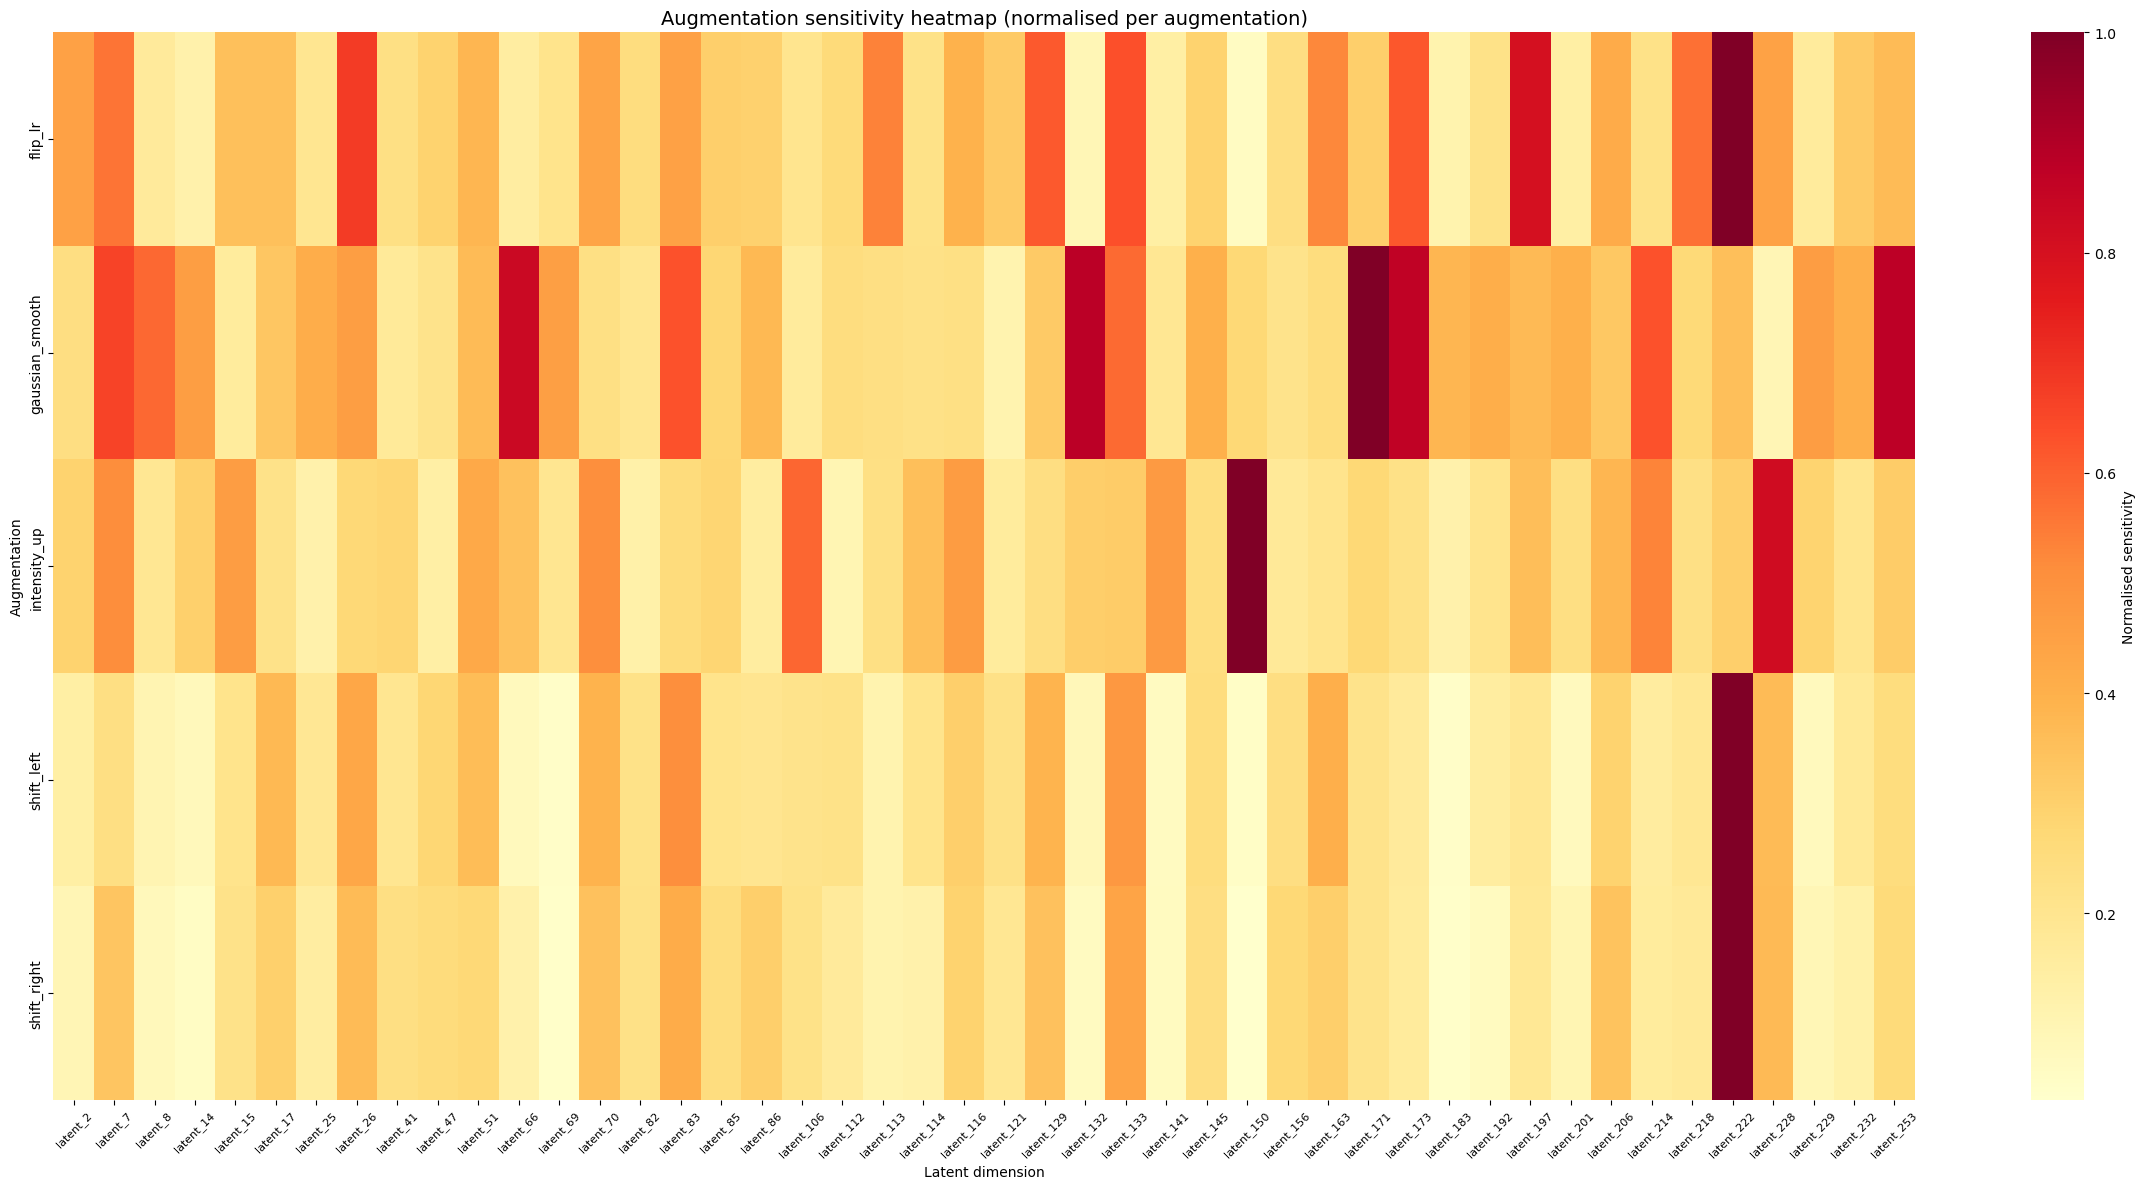

Saved.


In [15]:
# [VISUALISATION]
# Heatmap: augmentation × top sensitive dimensions

# Collect top 20 dims across all augmentations (excluding gaussian_noise)
augs_to_plot = ['shift_left', 'shift_right', 'intensity_up', 'flip_lr', 'gaussian_smooth']

top_dims = set()
for aug_name in augs_to_plot:
    top = (df_mean[df_mean['aug'] == aug_name]
           .nlargest(20, 'mean_abs_delta')['dim'].tolist())
    top_dims.update(top)

# Always include key dims
top_dims.update(['latent_132', 'latent_173', 'latent_114', 'latent_218'])
top_dims = sorted(top_dims, key=lambda x: int(x.replace('latent_', '')))

# Pivot table
df_heatmap = (df_mean[df_mean['aug'].isin(augs_to_plot)]
              .pivot(index='aug', columns='dim', values='mean_abs_delta')
              [top_dims])

# Normalise per augmentation row (0-1)
df_norm = df_heatmap.div(df_heatmap.max(axis=1), axis=0)

fig, ax = plt.subplots(figsize=(24, 12))
sns.heatmap(df_norm, cmap='YlOrRd', ax=ax, cbar_kws={'label': 'Normalised sensitivity'})
ax.set_title('Augmentation sensitivity heatmap (normalised per augmentation)', fontsize=14)
ax.set_xlabel('Latent dimension')
ax.set_ylabel('Augmentation')
plt.xticks(rotation=45, fontsize=8)
plt.tight_layout()
plt.savefig('../../results/figures/augmentation_sensitivity_heatmap.png', dpi=150)
plt.show()
print("Saved.")

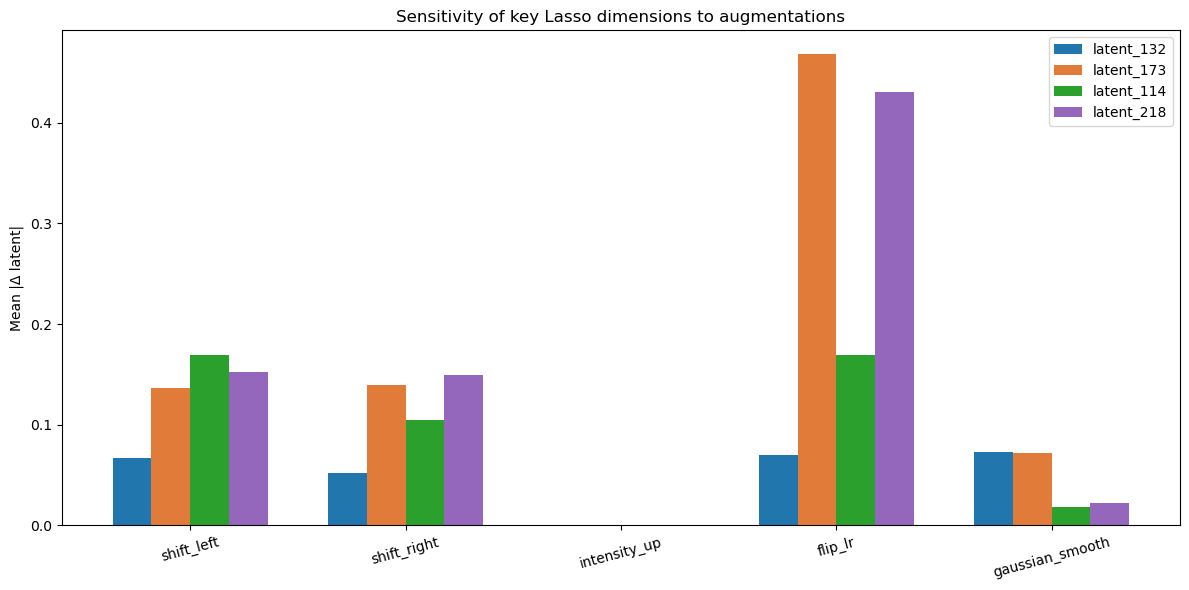

Saved.


In [16]:
# [KEY-DIMS-PLOT]
# ─────────────────────────────────────────────────────────────────
# Bar plot: sensitivity of key Lasso dimensions per augmentation
# ─────────────────────────────────────────────────────────────────

key_dims = ['latent_132', 'latent_173', 'latent_114', 'latent_218']
augs_to_plot = ['shift_left', 'shift_right', 'intensity_up', 'flip_lr', 'gaussian_smooth']

df_key = df_mean[
    df_mean['dim'].isin(key_dims) &
    df_mean['aug'].isin(augs_to_plot)
].copy()

fig, ax = plt.subplots(figsize=(12, 6))
x = np.arange(len(augs_to_plot))
width = 0.18
colors = ['#2176ae', '#e07b39', '#2ca02c', '#9467bd']

for i, dim in enumerate(key_dims):
    vals = [df_key[(df_key['aug'] == aug) & (df_key['dim'] == dim)]['mean_abs_delta'].values[0]
            for aug in augs_to_plot]
    ax.bar(x + i * width, vals, width, label=dim, color=colors[i])

ax.set_xticks(x + width * 1.5)
ax.set_xticklabels(augs_to_plot, rotation=15)
ax.set_ylabel('Mean |Δ latent|')
ax.set_title('Sensitivity of key Lasso dimensions to augmentations')
ax.legend()
plt.tight_layout()
plt.savefig('../../results/figures/augmentation_top_dims.png', dpi=150)
plt.show()
print("Saved.")

## 7. Sanity Check

In [17]:
# [RECONSTRUCTION-SANITY-CHECK]

# ICV normalisation (same as training) 
_mask = nib.load(MASK_PATH).get_fdata().astype(bool)   # already defined in CONFIG

def normalize_volume(vol):
    vol = vol - vol.min()
    vol = vol * _mask
    vol = vol / np.mean(vol[_mask])
    return vol

_val_tf = Compose([
    SpatialCropd(keys=['image'], roi_slices=[slice(9, 73), slice(None), slice(None)]),
    SpatialPadd(keys=['image'], spatial_size=[64, 128, 128], mode='constant', constant_values=0),
])

def load_and_transform(dcm_path):
    vol = pydicom.dcmread(str(dcm_path)).pixel_array.astype(np.float32)
    vol = normalize_volume(vol)
    d = _val_tf({'image': vol[np.newaxis, ...]})
    return torch.tensor(np.array(d['image'])).float().unsqueeze(0).to(DEVICE)

# pick 3 PD + 3 HC subjects
GROUPS_RC = {
    'PD': Path(IMAGES_ROOT) / 'PPMI_Images_PD',
    'HC': Path(IMAGES_ROOT) / 'PPMI_Images_Cont',
}

def first_dcm(root):
    for p in sorted(Path(root).rglob('*.dcm')):
        return p

subjects_rc = []
for label, folder in GROUPS_RC.items():
    for subj_dir in sorted(folder.iterdir())[:3]:
        dcm = first_dcm(subj_dir)
        if dcm:
            subjects_rc.append({'label': label, 'dcm': dcm, 'name': subj_dir.name})

print(f"Subjects selected: {len(subjects_rc)}")

# encode → decode
results_rc = []
with torch.no_grad():
    for s in subjects_rc:
        t = load_and_transform(s['dcm'])
        recon, mu = model(t)          # model is the VAEWrapper already loaded
        orig_np  = t[0, 0].cpu().numpy()
        recon_np = recon[0, 0].cpu().numpy()
        mse = np.mean((orig_np - recon_np) ** 2)
        print(f"  {s['label']}  {s['name'][:16]:16s}  MSE={mse:.4f}  "
              f"μ range [{mu.min():.2f}, {mu.max():.2f}]")
        results_rc.append({**s, 'orig': orig_np, 'recon': recon_np, 'mse': mse})

Subjects selected: 4


/var/folders/x_/6yv4myms0vgby9kqty8ns9wh0000gr/T/ipykernel_40780/1805029360.py:21: DeprecationWarning: __array__ implementation doesn't accept a copy keyword, so passing copy=False failed. __array__ must implement 'dtype' and 'copy' keyword arguments. To learn more, see the migration guide https://numpy.org/devdocs/numpy_2_0_migration_guide.html#adapting-to-changes-in-the-copy-keyword
  return torch.tensor(np.array(d['image'])).float().unsqueeze(0).to(DEVICE)


  PD  100001            MSE=0.0322  μ range [-1.51, 1.79]
  PD  100002            MSE=0.0360  μ range [-1.48, 1.76]
  HC  100004            MSE=0.0327  μ range [-1.53, 1.45]
  HC  100890            MSE=0.0345  μ range [-2.74, 1.66]


Saved → results/figures/reconstruction_sanity_check_v2.png


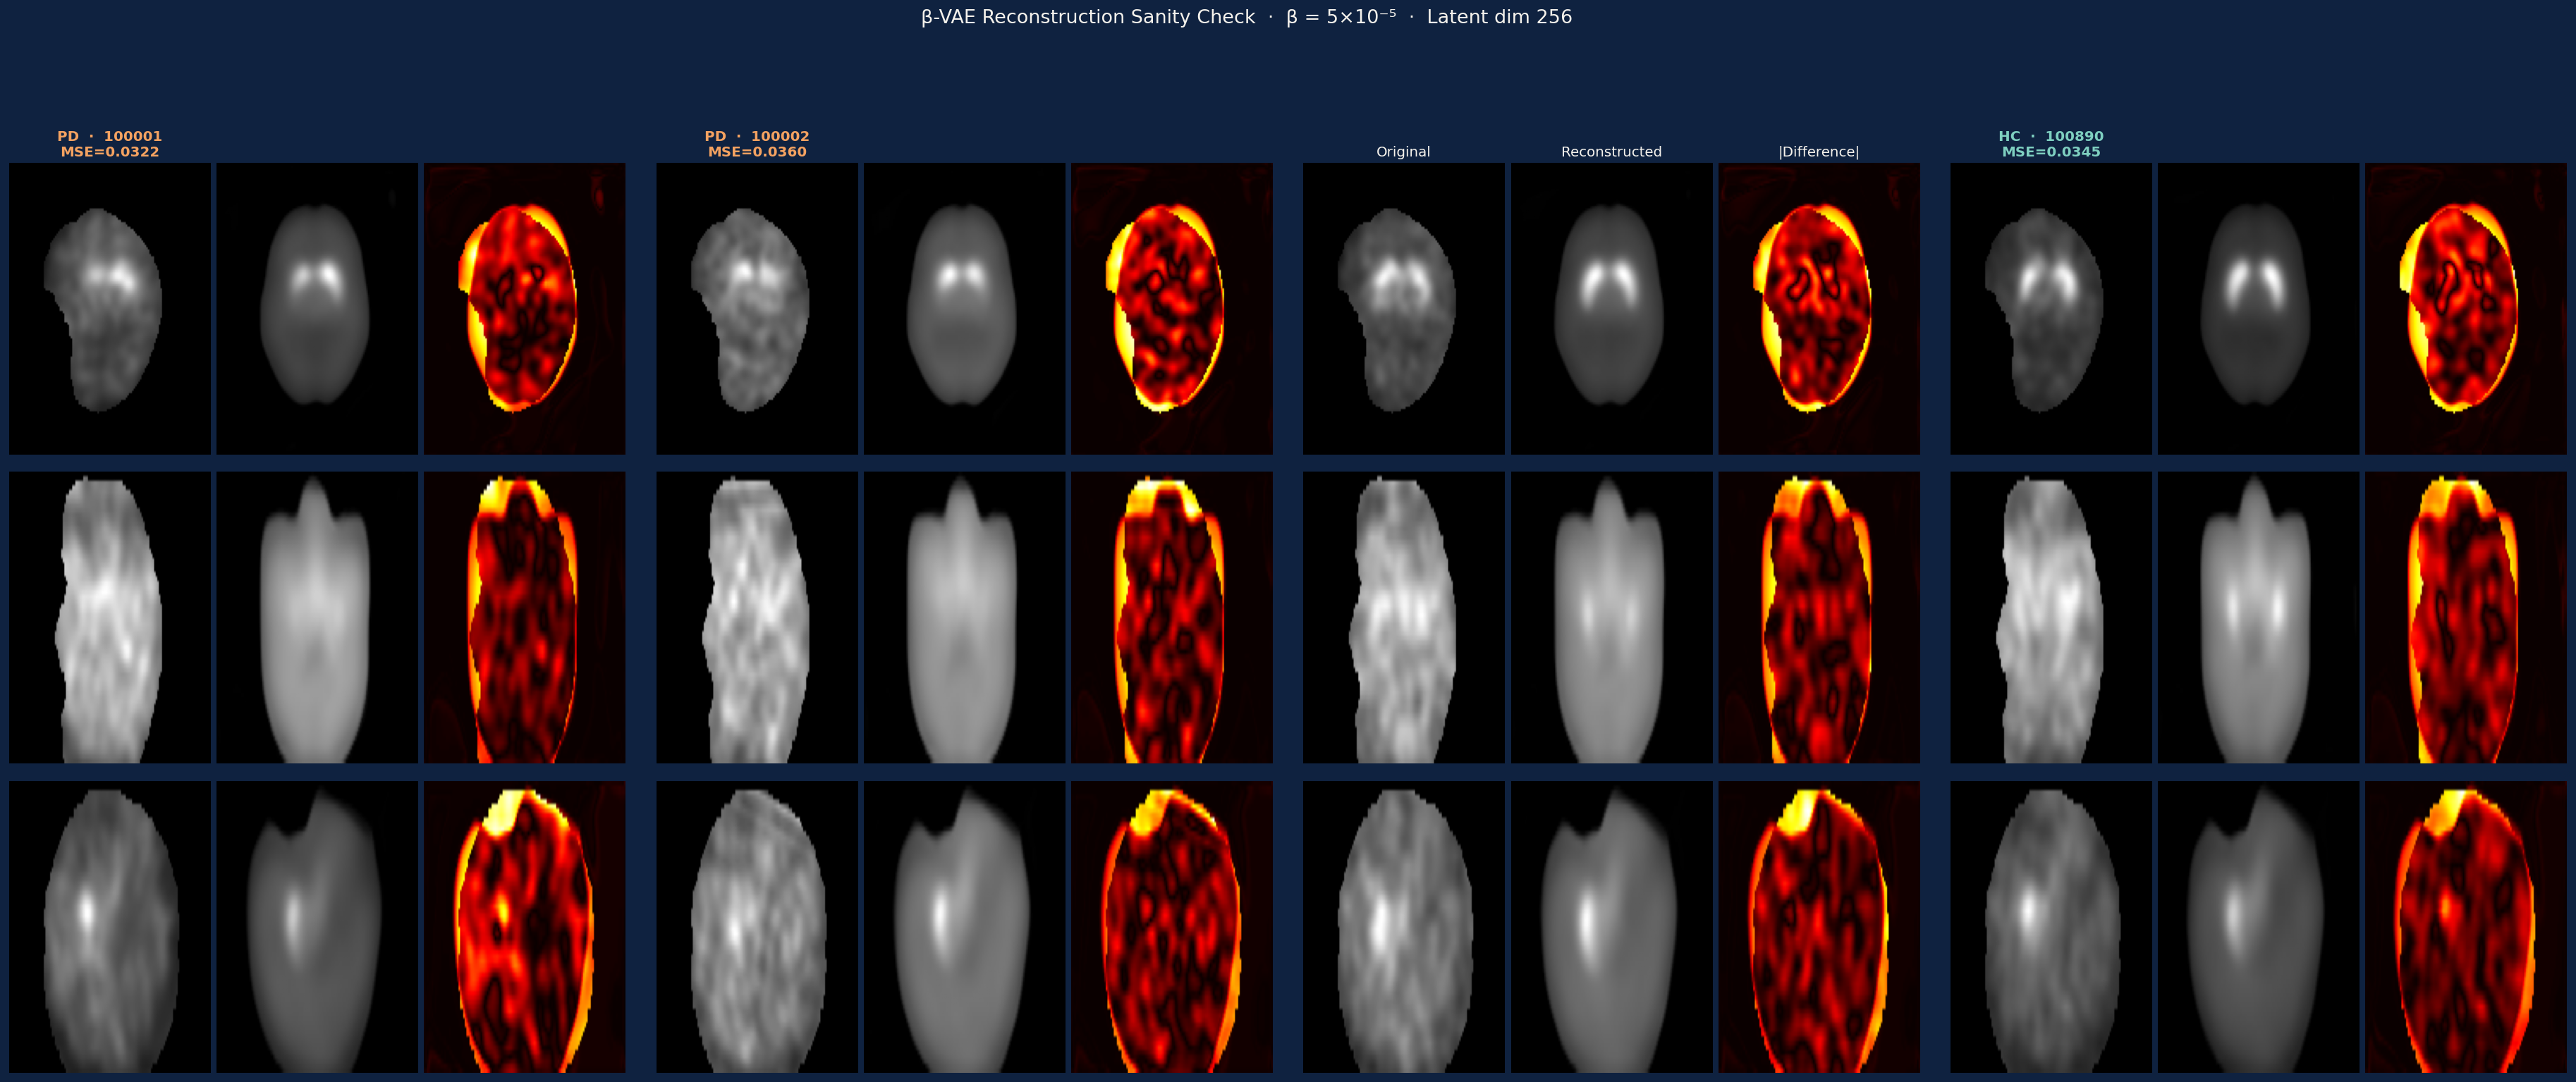

In [22]:
import matplotlib.gridspec as gridspec

# Plot
N = len(results_rc)
fig = plt.figure(figsize=(N * 9, 3 * 3.8 + 1.5), facecolor='#0F2240')
outer = gridspec.GridSpec(1, N, figure=fig, wspace=0.05)

def get_slices(vol):
    return [
        vol[30, :, :],   # axial — striatal level (caudate/putamen)
        vol[:, 64, :],   # coronal
        vol[:, :, 64],   # sagittal
    ]

slice_labels = ['Axial\n(striatum)', 'Coronal', 'Sagittal']

for si, res in enumerate(results_rc):
    inner = gridspec.GridSpecFromSubplotSpec(3, 3, subplot_spec=outer[si],
                                             wspace=0.03, hspace=0.06)
    os_ = get_slices(res['orig'])
    rs_ = get_slices(res['recon'])
    lc  = '#7ECFC0' if res['label'] == 'HC' else '#F4A261'

    for row, (o, r, sl) in enumerate(zip(os_, rs_, slice_labels)):
        diff = np.abs(o - r)
        vmax = max(o.max(), r.max()) + 1e-8
        for col, (img, cmap) in enumerate([(o,'gray'), (r,'gray'), (diff,'hot')]):
            ax = fig.add_subplot(inner[row, col])
            ax.imshow(img, cmap=cmap, vmin=0,
                      vmax=vmax if col < 2 else None, aspect='auto')
            ax.axis('off')
            if col == 0 and row == 0:
                titles = ['Original', 'Reconstructed', '|Difference|']
                ax.set_title(f"{res['label']}  ·  {res['name'][:14]}\nMSE={res['mse']:.4f}",
                             fontsize=11, color=lc, pad=5, fontweight='bold')
            if col == 0:
                ax.set_ylabel(sl, fontsize=9, color='#A8C0C0',
                              rotation=0, labelpad=50, va='center')

# column headers on middle subject
mid = N // 2
for col, title in enumerate(['Original', 'Reconstructed', '|Difference|']):
    ax0 = fig.axes[mid * 9 + col]     # first row axes for middle subject
    ax0.set_title(title, fontsize=11, color='#F5F2EC', pad=5)

fig.suptitle('β-VAE Reconstruction Sanity Check  ·  β = 5×10⁻⁵  ·  Latent dim 256',
             fontsize=15, color='#F5F2EC', y=1.01, fontweight='300')
plt.savefig(os.path.join(FIGURES_DIR, 'reconstruction_sanity_check_v2.png'),
            dpi=130, bbox_inches='tight', facecolor='#0F2240')
plt.close()
print("Saved → results/figures/reconstruction_sanity_check_v2.png")
from IPython.display import Image, display
with open(os.path.join(FIGURES_DIR, 'reconstruction_sanity_check_v2.png'), 'rb') as f:
    display(Image(data=f.read()))

Shape: (64, 128, 128)
z=30 slice max: 3.527
z=30 slice sum: 5963.1


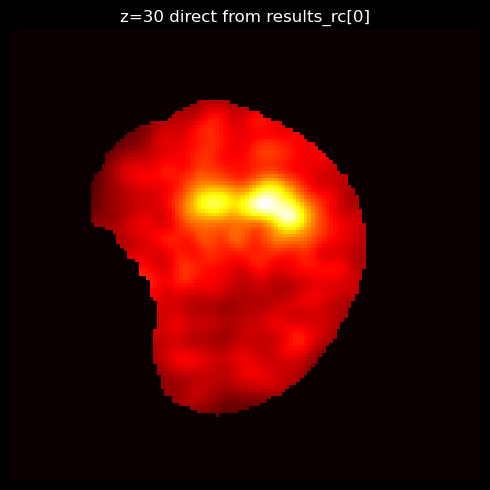

In [19]:
vol = results_rc[0]['orig']
print(f"Shape: {vol.shape}")          # should be (64, 128, 128)
print(f"z=30 slice max: {vol[30].max():.3f}")
print(f"z=30 slice sum: {vol[30].sum():.1f}")

# Quick inline plot of just z=30
fig, ax = plt.subplots(1, 1, figsize=(5, 5), facecolor='black')
ax.imshow(vol[30], cmap='hot', aspect='auto')
ax.set_title(f'z=30 direct from results_rc[0]', color='white')
ax.axis('off')
plt.tight_layout()
with open('/tmp/test_slice.png', 'wb') as f:
    plt.savefig(f, dpi=100, bbox_inches='tight', facecolor='black')
plt.close()
from IPython.display import Image, display
with open('/tmp/test_slice.png', 'rb') as f:
    display(Image(data=f.read()))

Volume shape: (64, 128, 128)
Axial dim range: 0–63


/var/folders/x_/6yv4myms0vgby9kqty8ns9wh0000gr/T/ipykernel_40780/1805029360.py:21: DeprecationWarning: __array__ implementation doesn't accept a copy keyword, so passing copy=False failed. __array__ must implement 'dtype' and 'copy' keyword arguments. To learn more, see the migration guide https://numpy.org/devdocs/numpy_2_0_migration_guide.html#adapting-to-changes-in-the-copy-keyword
  return torch.tensor(np.array(d['image'])).float().unsqueeze(0).to(DEVICE)


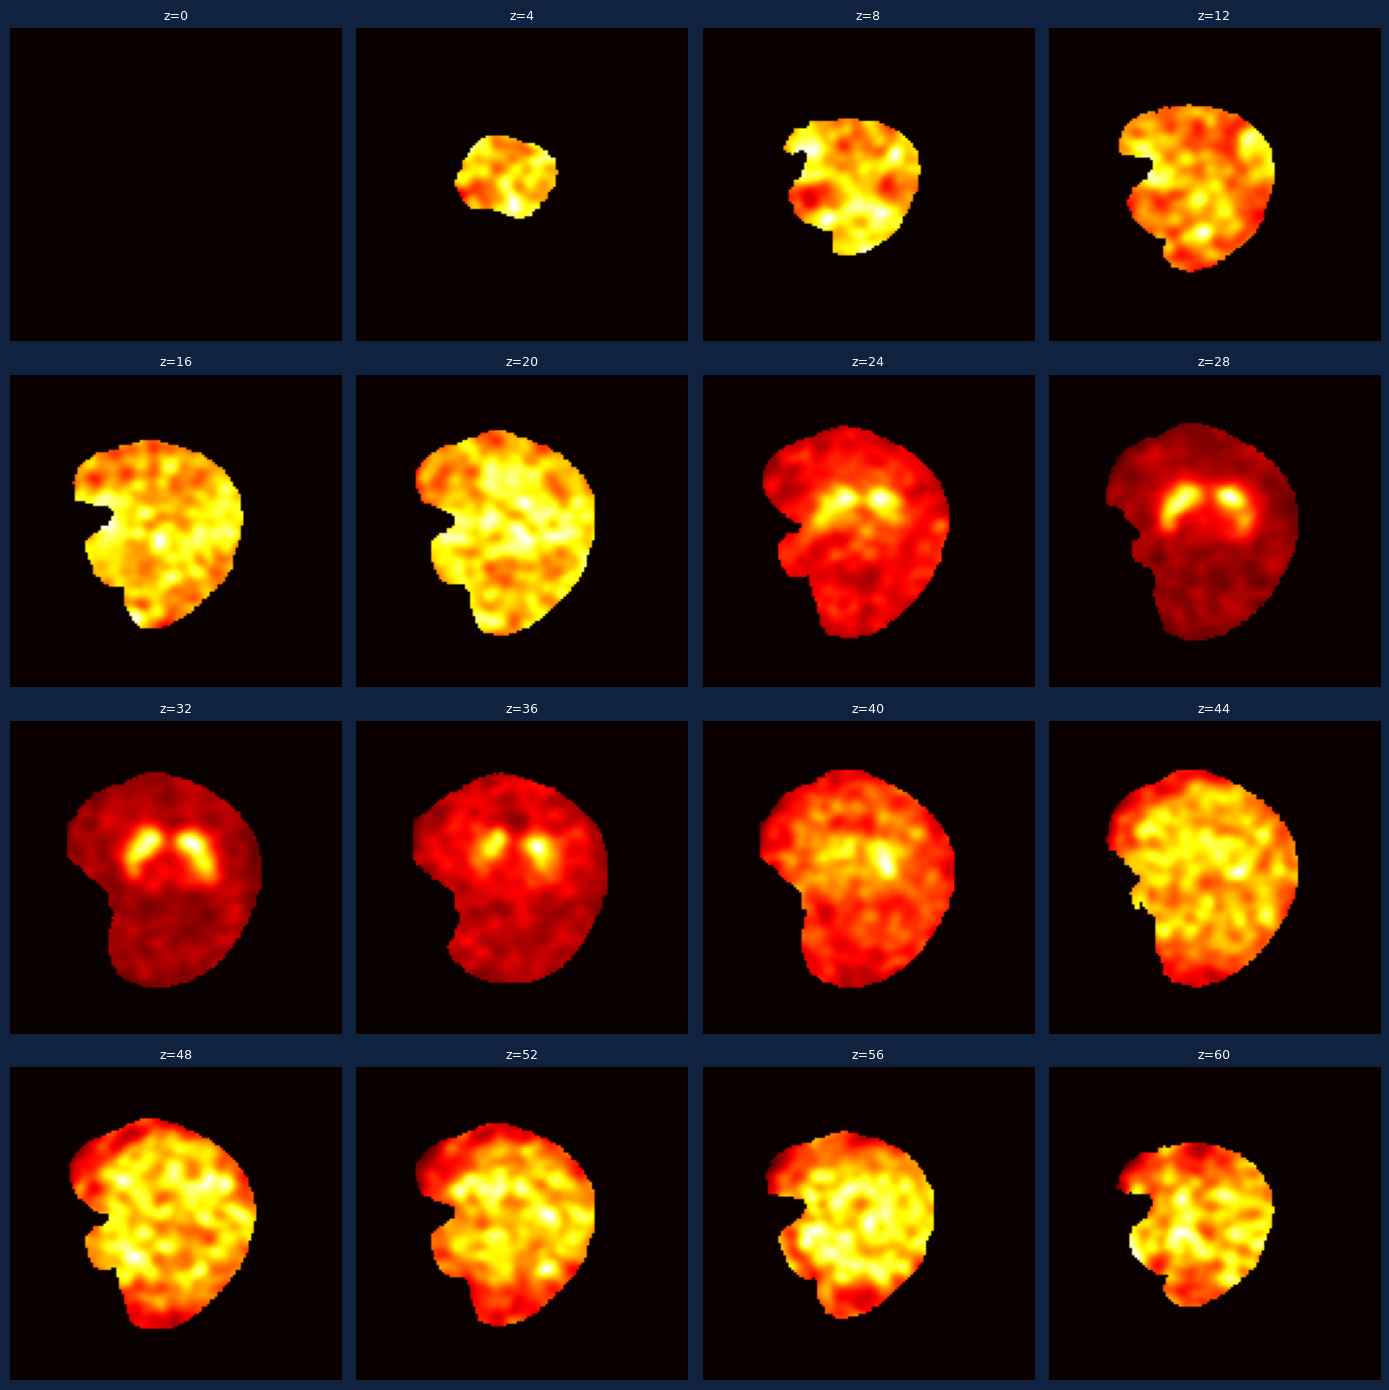

Saved axial_sweep.png


In [20]:
# Find the striatal slice — look for the two bright caudate/putamen spots
import matplotlib.pyplot as plt

# Load one subject
test_tensor = load_and_transform(df_selected.iloc[0]['dcm_path'])
vol = test_tensor[0, 0].cpu().numpy()   # (64, 128, 128) after crop+pad

print(f"Volume shape: {vol.shape}")
print(f"Axial dim range: 0–{vol.shape[0]-1}")

# Plot every 4th axial slice to find where striatum appears
fig, axes = plt.subplots(4, 4, figsize=(14, 14), facecolor='#0F2240')
for i, ax in enumerate(axes.flat):
    sl_idx = i * 4
    ax.imshow(vol[sl_idx, :, :], cmap='hot', aspect='auto')
    ax.set_title(f'z={sl_idx}', color='white', fontsize=9)
    ax.axis('off')
plt.tight_layout()
plt.savefig('../../results/figures/axial_sweep.png', dpi=100,
            bbox_inches='tight', facecolor='#0F2240')
plt.show()
print("Saved axial_sweep.png")

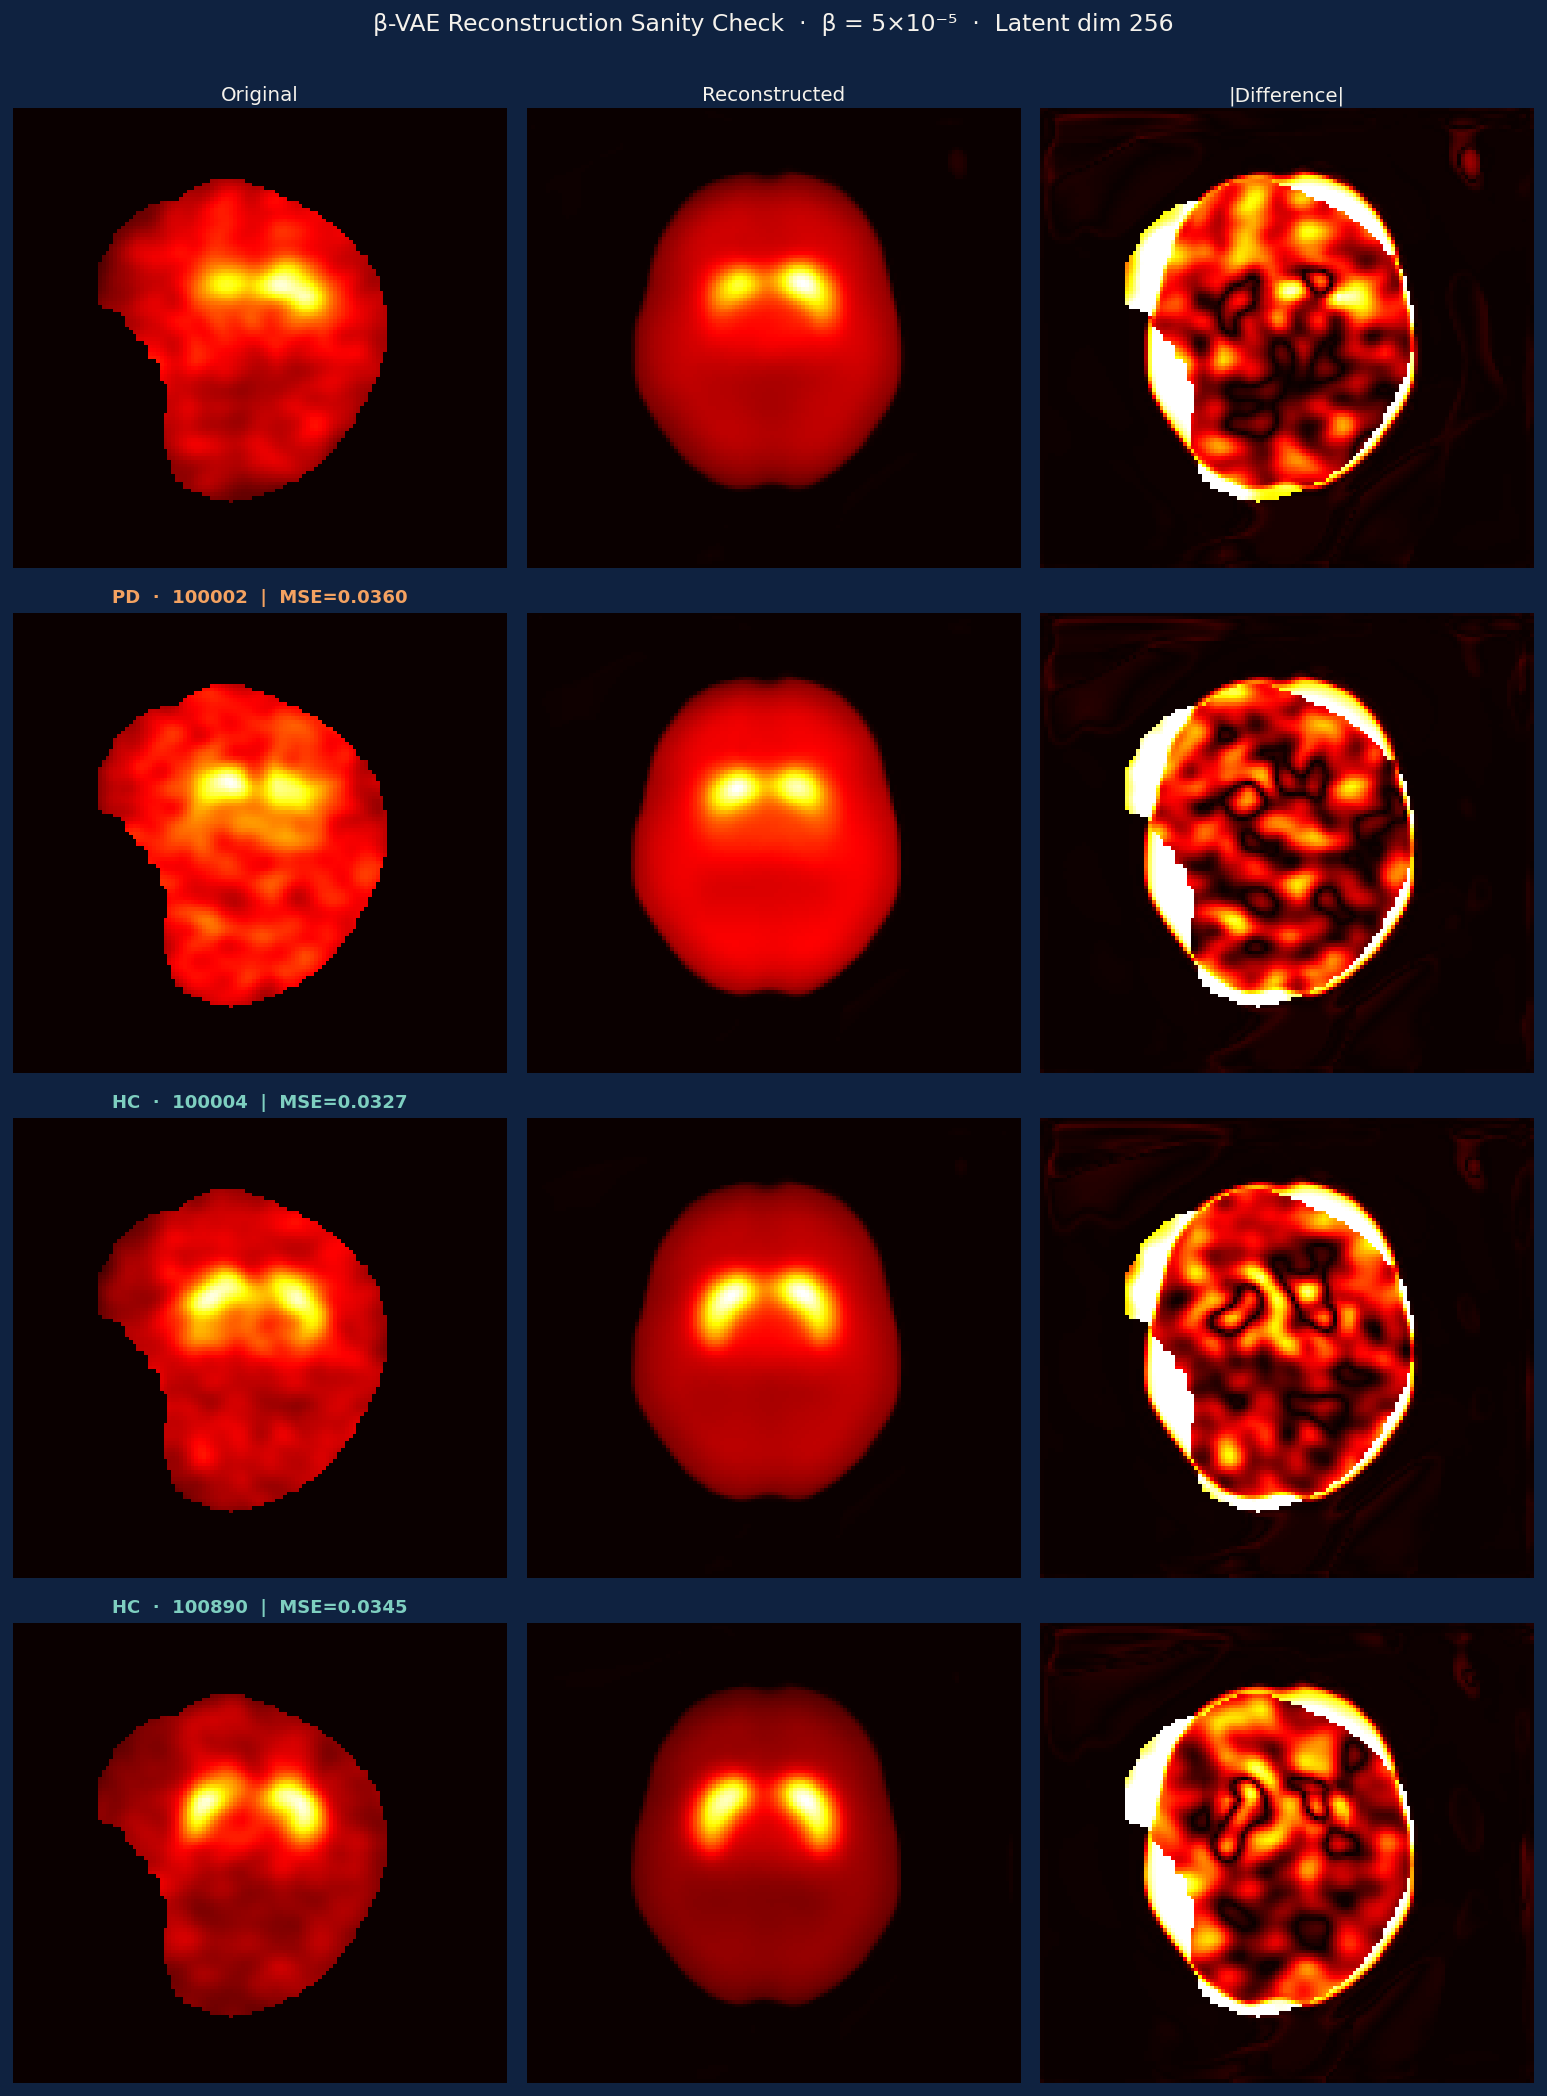

In [25]:
fig, axes = plt.subplots(len(results_rc), 3, figsize=(12, 4 * len(results_rc)),
                         facecolor='#0F2240')
axes = np.array(axes)

for si, res in enumerate(results_rc):
    o = res['orig'][30, :, :]
    r = res['recon'][30, :, :]
    d = np.abs(o - r)
    vmax = max(o.max(), r.max()) + 1e-8
    lc  = '#7ECFC0' if res['label'] == 'HC' else '#F4A261'

    axes[si, 0].imshow(o, cmap='hot', vmin=0, vmax=vmax, aspect='auto')
    axes[si, 0].set_title(f"{res['label']}  ·  {res['name'][:10]}  |  MSE={res['mse']:.4f}",
                          color=lc, fontsize=10, fontweight='bold')
    axes[si, 0].set_ylabel('Axial z=30\n(striatum)', color='#A8C0C0', fontsize=8,
                            rotation=0, labelpad=55, va='center')
    axes[si, 0].axis('off')

    axes[si, 1].imshow(r, cmap='hot', vmin=0, vmax=vmax, aspect='auto')
    axes[si, 1].axis('off')

    axes[si, 2].imshow(d, cmap='hot', vmax=np.percentile(d, 97), aspect='auto')
    axes[si, 2].axis('off')

# Column headers on row 0 only
for col, title in enumerate(['Original', 'Reconstructed', '|Difference|']):
    axes[0, col].set_title(title, color='#F5F2EC', fontsize=11, pad=4)

fig.suptitle('β-VAE Reconstruction Sanity Check  ·  β = 5×10⁻⁵  ·  Latent dim 256',
             fontsize=13, color='#F5F2EC', y=1.005, fontweight='300')

plt.tight_layout()
out_path = os.path.join(FIGURES_DIR, 'reconstruction_sanity_check_v3.png')
plt.savefig(out_path, dpi=130, bbox_inches='tight', facecolor='#0F2240')
plt.close()

from IPython.display import Image, display
with open(out_path, 'rb') as f:
    display(Image(data=f.read()))